## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/Users/laxmigupte/Desktop/Ironhack/week2/D4/amz_uk_price_prediction_dataset 13.40.08.csv")

In [3]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [5]:
df.shape

(2443651, 9)

In [7]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [8]:
df.duplicated().sum()

0

In [10]:
num = df.select_dtypes(include="number")
cat = df.select_dtypes(exclude="number")

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

In [61]:
crosstab_result2 = pd.crosstab(cat['category'], cat['isBestSeller']).head(20)
crosstab_result2

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
Agricultural Equipment & Supplies,8421,109
Alexa Built-In Devices,106,1
Art & Craft Supplies,253,5
Arts & Crafts,9319,230


In [62]:
crosstab_result2['proportion'] = crosstab_result2[True] / crosstab_result2.sum(axis=1)

In [66]:
sorted_best_sellers = crosstab_result2.sort_values(by='proportion', ascending=False).head(20)
sorted_best_sellers

isBestSeller,False,True,proportion
category,,,
Bakeware,233,6,0.025105
Arts & Crafts,9319,230,0.024086
Baby,14709,341,0.022658
Abrasive & Finishing Products,245,5,0.020000
Art & Craft Supplies,253,5,0.019380
Agricultural Equipment & Supplies,8421,109,0.012778
Bathroom Linen,401,5,0.012315
Adapters,251,3,0.011811
Bass Guitars & Gear,523,5,0.009470


The category 'Grocery' is more prevalent for being a best-seller

2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.


In [67]:
from scipy.stats import chi2_contingency

In [68]:
crosstab_result2

isBestSeller,False,True,proportion
category,,,
3D Printers,247,1,0.004032
3D Printing & Scanning,4065,2,0.000492
Abrasive & Finishing Products,245,5,0.020000
Action Cameras,1696,1,0.000589
Adapters,251,3,0.011811
Agricultural Equipment & Supplies,8421,109,0.012778
Alexa Built-In Devices,106,1,0.009346
Art & Craft Supplies,253,5,0.019380
Arts & Crafts,9319,230,0.024086


In [69]:
# Chi-square test for 'isBestSeller' and 'category'
_, chi2_pvalue, _, _  = chi2_contingency(crosstab_result2)

In [70]:
type(chi2_pvalue)

numpy.float64

In [71]:
float(chi2_pvalue)

2.4165338493997677e-188

In [49]:
float(chi2_pvalue) <0.05
# If the p value is smaller than 0.05 (or alpha) we do have a correlation between 2 categorical variables
# Else, nothigness

True

A Chi-square test to determines the best-seller distribution is not independent of the product category. THERE IS CORRELATION BETWEEN THEM.

In [72]:
from scipy.stats.contingency import association

In [74]:
counts_only = crosstab_result2.drop(columns=['proportion'])

In [75]:
# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(counts_only, method='cramer')

0.1048206680788083

Using Cramér's, the strength of association between best-seller status and category is 0.122.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.


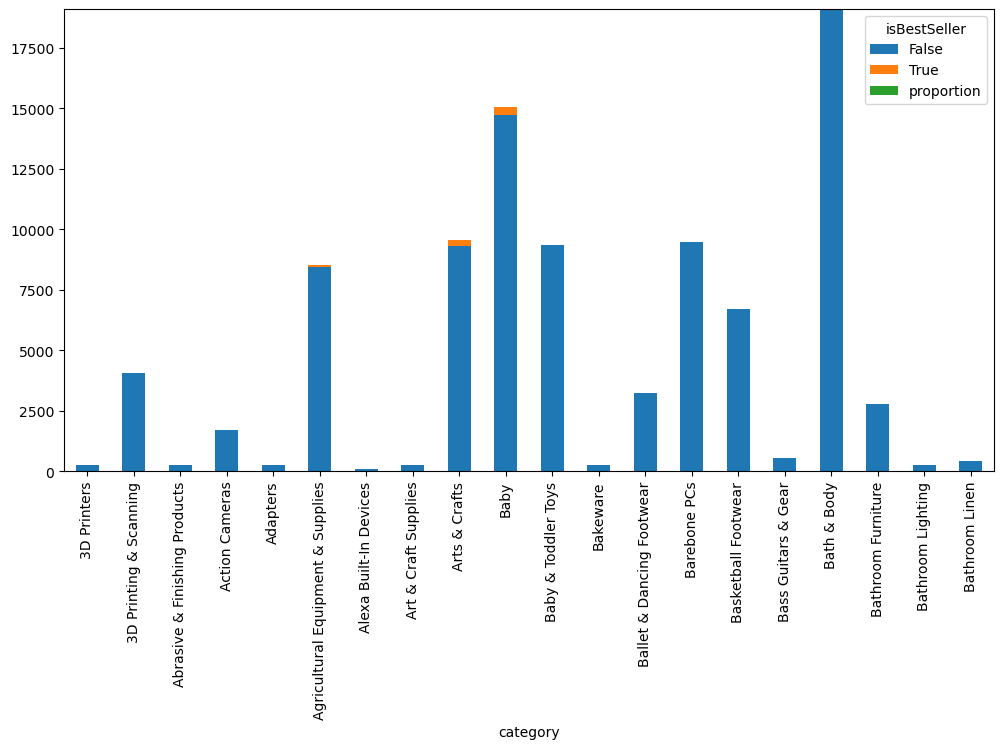

In [76]:
crosstab_result2.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*


In [79]:
# 1. Calculate Q1 (25th percentile) and Q3 (75th percentile)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
# 2. Calculate the IQR
IQR = Q3 - Q1
IQR

36.0

In [81]:
# 3. Define the Upper and Lower bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
lower_bound , upper_bound

(-44.01, 99.99000000000001)

In [82]:
# 4. Filter the dataframe to remove outliers
# We keep only rows where price is between the lower and upper bounds
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]
df_no_outliers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

In [87]:
# 1. Identify the top 20 most frequent categories
top_20_cat_names = df_no_outliers['category'].value_counts().head(20).index

# 2. Filter the dataframe to include ONLY those 20 categories
df_top_20 = df_no_outliers[df_no_outliers['category'].isin(top_20_cat_names)]

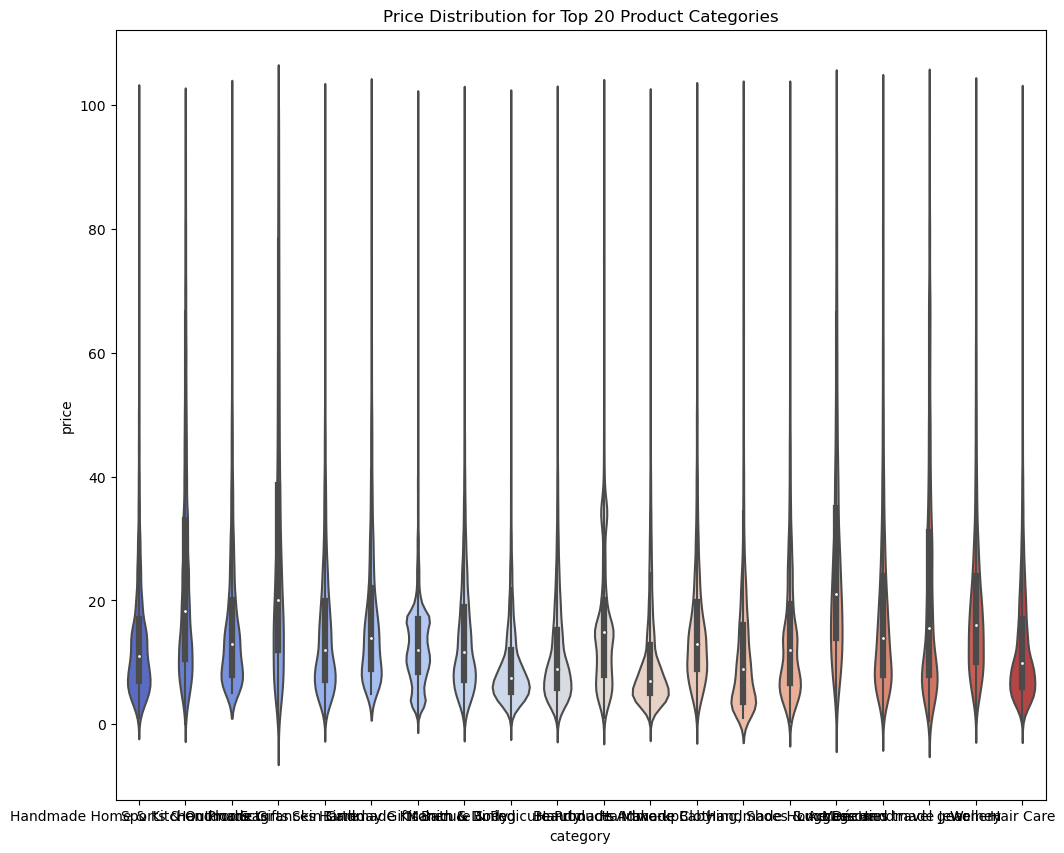

In [88]:
# 3. Create the violin plot
plt.figure(figsize=(12, 10)) # Increase figure size for readability
sns.violinplot(data=df_top_20, x="category", y="price", palette="coolwarm")

plt.title('Price Distribution for Top 20 Product Categories')
plt.show()

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

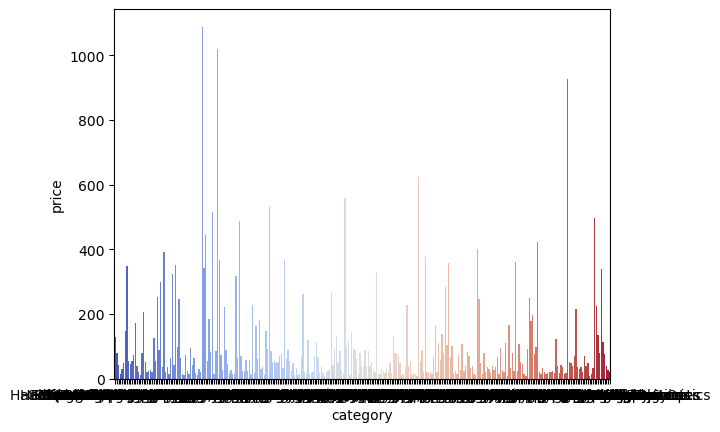

In [89]:
sns.barplot(data=df, x="category", y="price", palette="coolwarm", errorbar=None, estimator="mean")
plt.show()

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [90]:
# 1. Identify the top 10 most frequent categories
top_10_cat_names = df ['stars'].value_counts().head(10).index



In [93]:
# 2. Filter the dataframe to include ONLY those 10 categories
df_top_10 = df[df['stars'].isin(top_10_cat_names)]

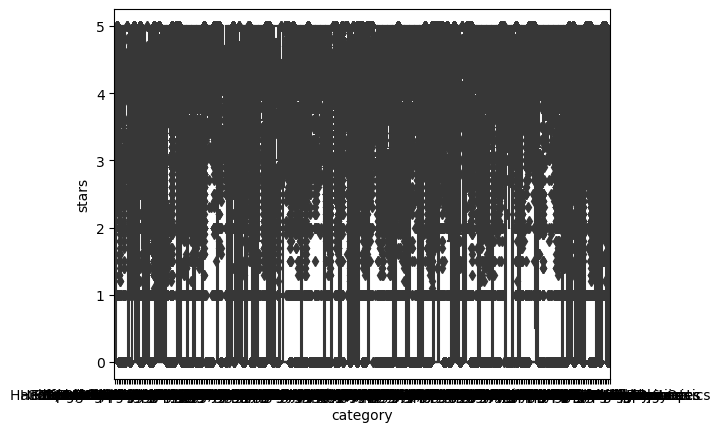

In [94]:
sns.boxplot(data=df, x="category", y="stars", palette="coolwarm")
plt.show()

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?

In [95]:
num.columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')

In [96]:
round(float(df["price"].corr(df["stars"], method="pearson")), 2)

-0.12

In [97]:
df["price"].corr(df["stars"], method="spearman")

-0.13316425462433937

In [98]:
round(float(df["price"].corr(df["stars"], method="spearman")), 2)

-0.13

 The **Pearson correlation** of \(-0.12\) suggests a strong positive linear relationship between the price of the products and its rating in stars. As the Rating increases, the price tends to increase as well.
  
- The **Spearman correlation** of \(-0.13\) indicates a strong positive monotonic relationship between the two variables. This means that when one variable increases, the other also tends to increase, but not necessarily at a constant rate.

The slightly higher value for Spearman correlation suggests that there might be some non-linear aspects to their relationship or the presence of outliers affecting the Pearson correlation.

In essence, both correlations emphasize that products with higher rating tend to have higher prices.

2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

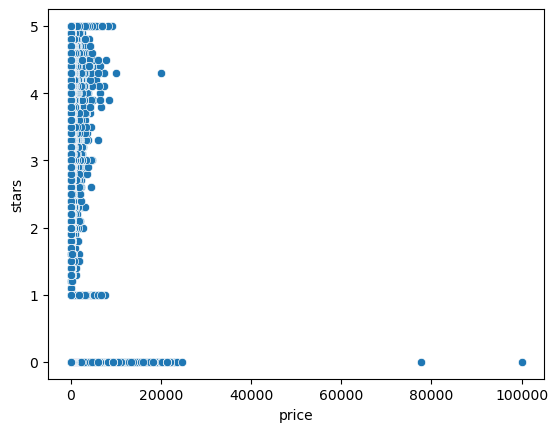

In [99]:
sns.scatterplot(data=df, x='price', y='stars')
plt.show()

In [100]:
correlation_matrix = num.corr()

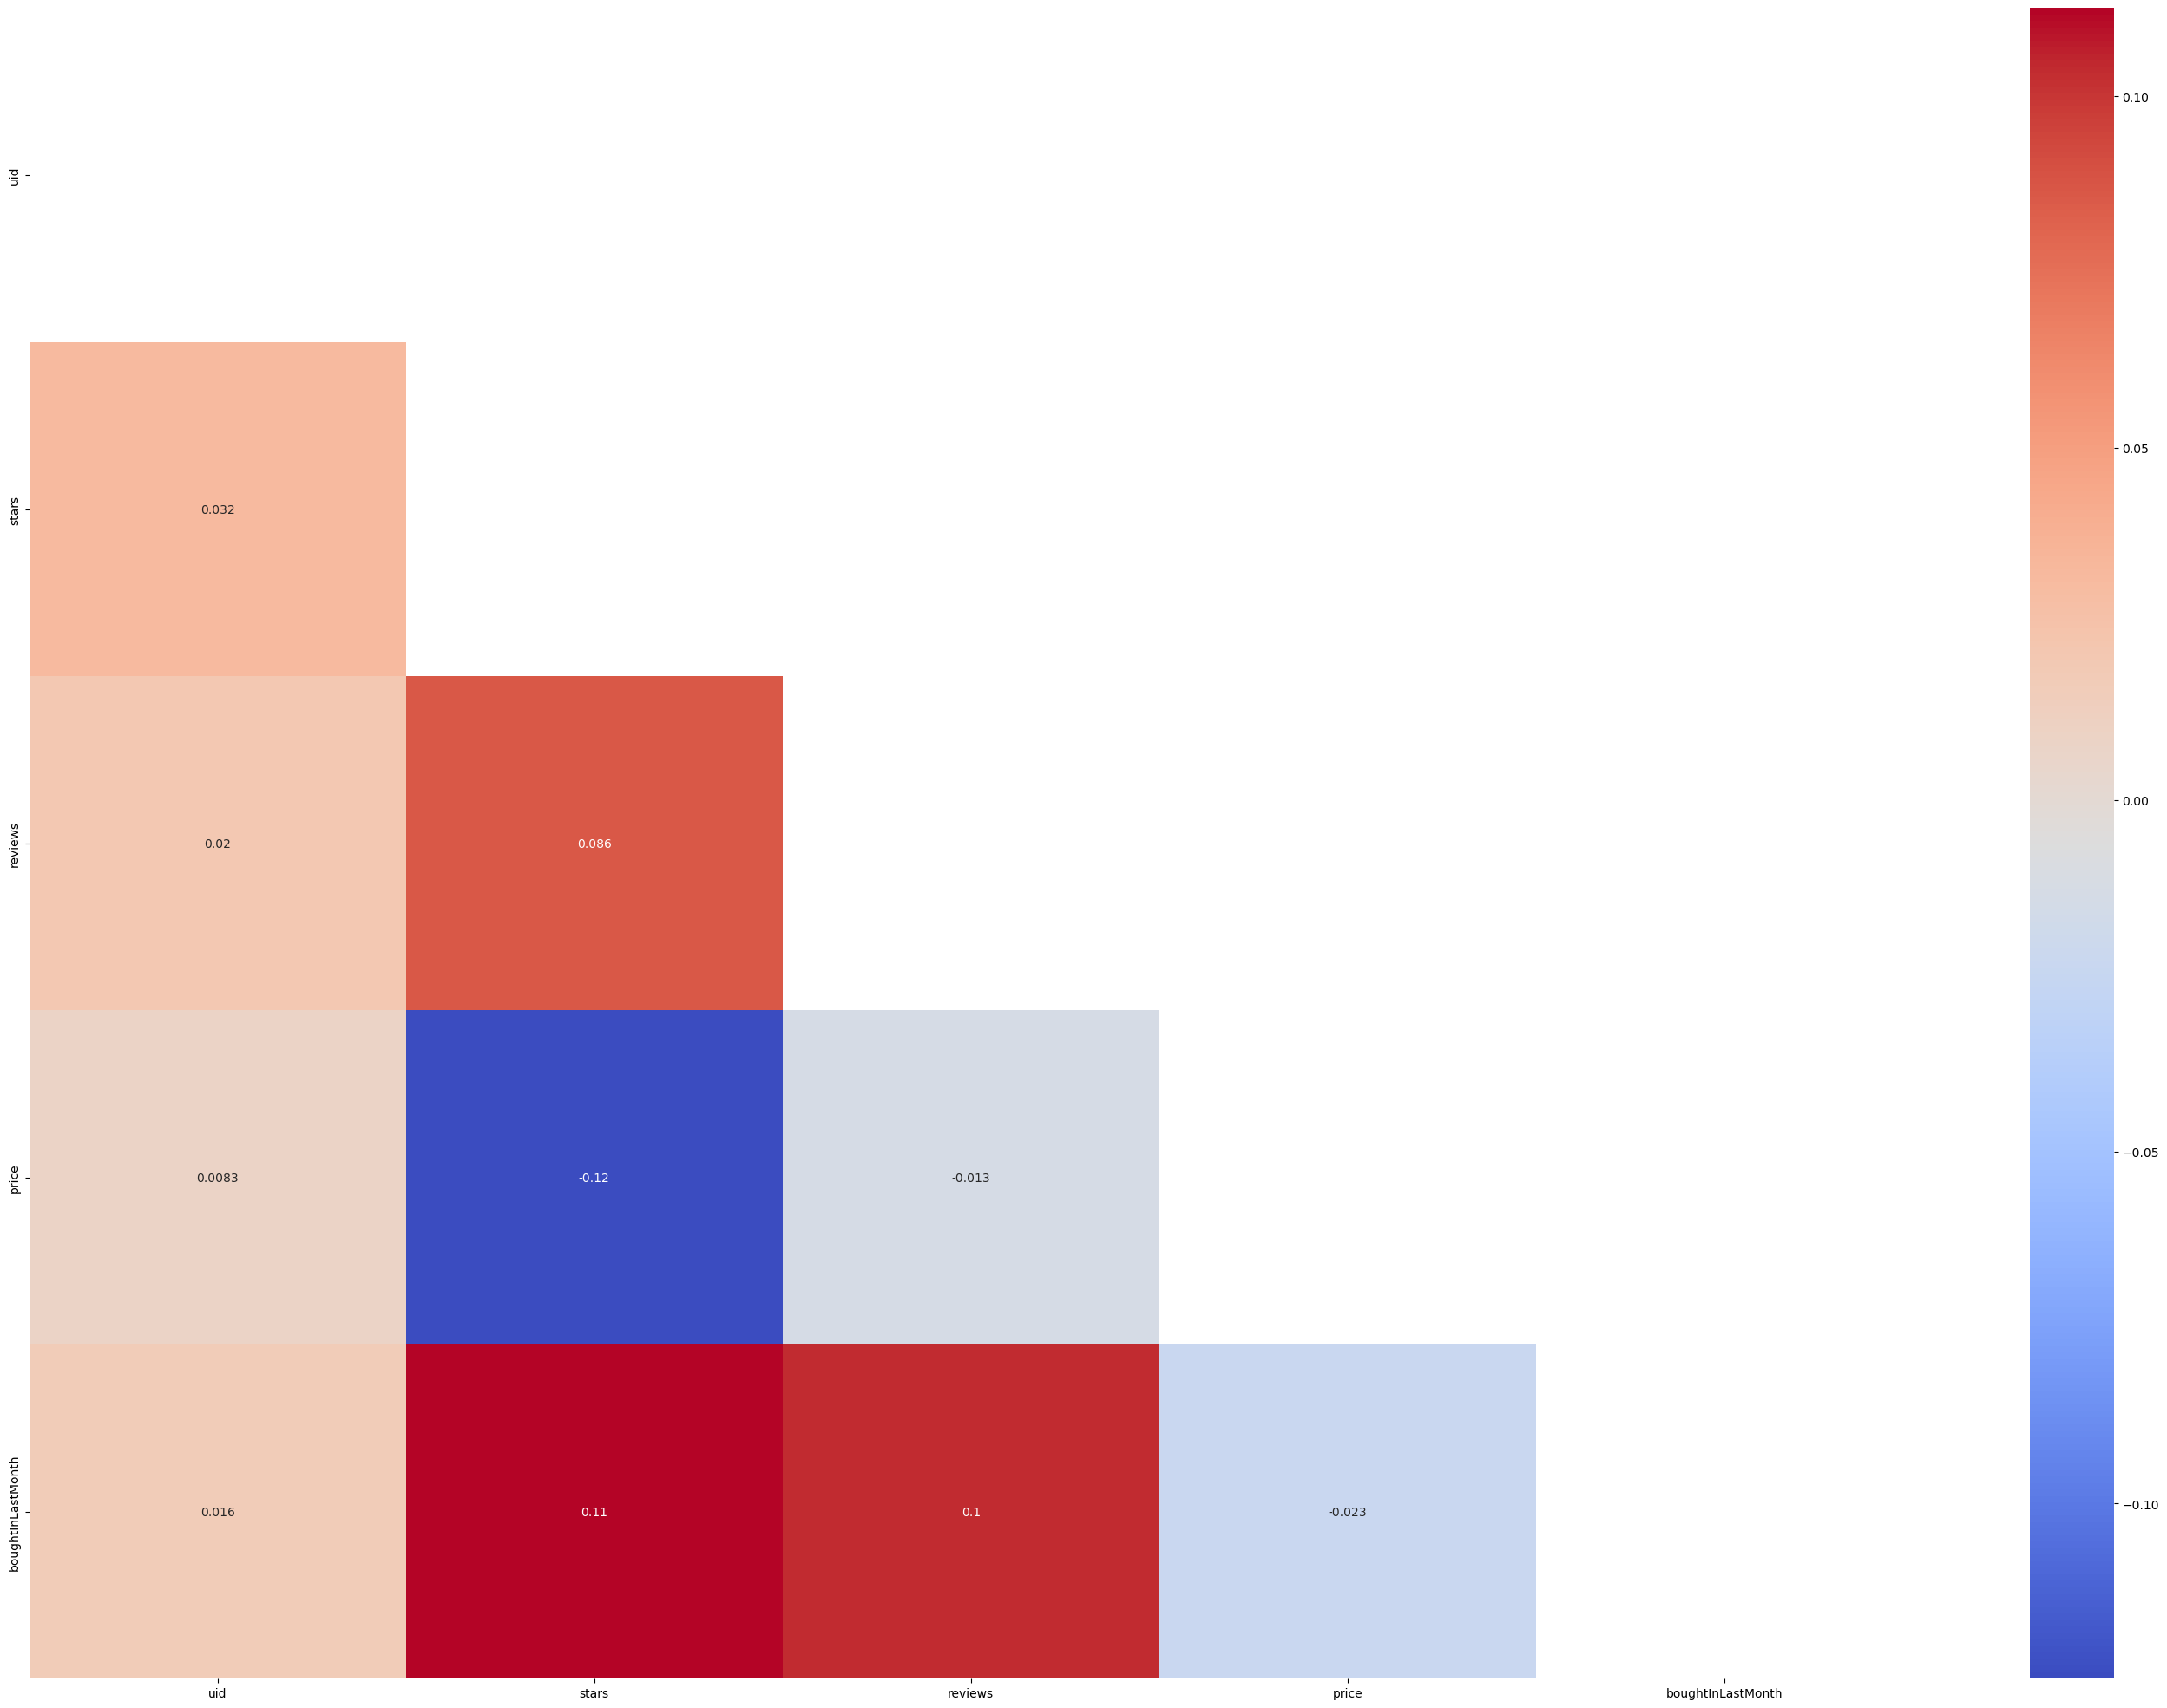

In [101]:
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
plt.figure(figsize=(35, 25))
sns.heatmap(correlation_matrix, mask=mask, annot=True, cmap="coolwarm")

plt.show()